# Decision Tree Comparison

In [1]:
# imports

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import cross_val_score


In [2]:
# paths

ROOT = Path.cwd()

while not (ROOT / "results" / "outputs").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

ORIGINAL_DIR = ROOT / "results" / "outputs" / "original"
NEW_DIR = ROOT / "results" / "outputs" / "new"

RESULT_DIR = ROOT / "results" / "model_results" / "decision_tree"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)


Project root: /home/kashmira/git/crop-soil-fertilizer


In [3]:
# load data

original_train = pd.read_csv(ORIGINAL_DIR / "train_processed.csv")
original_test = pd.read_csv(ORIGINAL_DIR / "test_processed.csv")

new_train = pd.read_csv(NEW_DIR / "train_processed.csv")
new_test = pd.read_csv(NEW_DIR / "test_processed.csv")

original_mapping = pd.read_csv(ORIGINAL_DIR / "label_mapping.csv")
new_mapping = pd.read_csv(NEW_DIR / "label_mapping.csv")

print("Original train:", original_train.shape)
print("Original test:", original_test.shape)

print("\nNew train:", new_train.shape)
print("New test:", new_test.shape)


Original train: (6400, 24)
Original test: (1600, 24)

New train: (3610, 36)
New test: (903, 36)


In [4]:
# prepare data

target = "Target_Label"

X_train_original = original_train.drop(columns=[target])
y_train_original = original_train[target]

X_test_original = original_test.drop(columns=[target])
y_test_original = original_test[target]

X_train_new = new_train.drop(columns=[target])
y_train_new = new_train[target]

X_test_new = new_test.drop(columns=[target])
y_test_new = new_test[target]


In [5]:
# evaluation

def evaluate_decision_tree(
    name,
    X_train,
    y_train,
    X_test,
    y_test,
):
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test)

    model = DecisionTreeClassifier(
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    cv_scores = cross_val_score(
        DecisionTreeClassifier(random_state=42),
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1,
    )

    result = {
        "Dataset": name,
        "Majority_Baseline": accuracy_score(y_test, baseline_pred),
        "Train_Accuracy": accuracy_score(y_train, train_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred),
        "Precision_Weighted": precision_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "Recall_Weighted": recall_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Weighted": f1_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Macro": f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0,
        ),
        "CV_Accuracy_Mean": cv_scores.mean(),
        "CV_Accuracy_Std": cv_scores.std(),
        "Tree_Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
    }

    return model, test_pred, result


In [6]:
# train both datasets

original_model, original_pred, original_result = evaluate_decision_tree(
    "Original",
    X_train_original,
    y_train_original,
    X_test_original,
    y_test_original,
)

new_model, new_pred, new_result = evaluate_decision_tree(
    "New",
    X_train_new,
    y_train_new,
    X_test_new,
    y_test_new,
)

results = pd.DataFrame([
    original_result,
    new_result,
])

display(results.round(4))


,Dataset,Majority_Baseline,Train_Accuracy,Test_Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,F1_Macro,CV_Accuracy_Mean,CV_Accuracy_Std,Tree_Depth,Leaves
0,Original,0.1488,1.0000,0.1462,0.1463,0.1462,0.1462,0.1460,0.1381,0.0075,35,3420
1,New,0.3023,0.9994,0.9324,0.9337,0.9324,0.9326,0.8368,0.8967,0.0080,27,657


In [7]:
# save results

results.to_csv(
    RESULT_DIR / "decision_tree_comparison.csv",
    index=False,
)

print("Saved:", RESULT_DIR / "decision_tree_comparison.csv")


Saved: /home/kashmira/git/crop-soil-fertilizer/results/model_results/decision_tree/decision_tree_comparison.csv


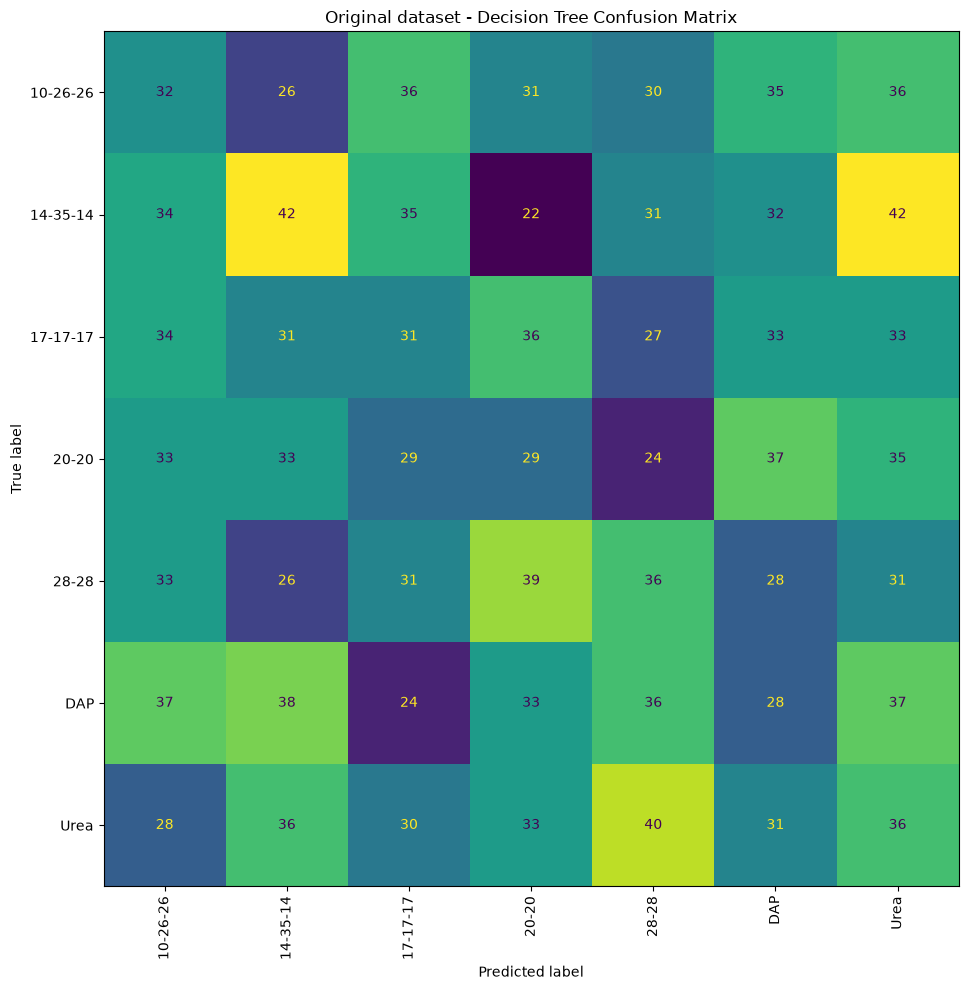

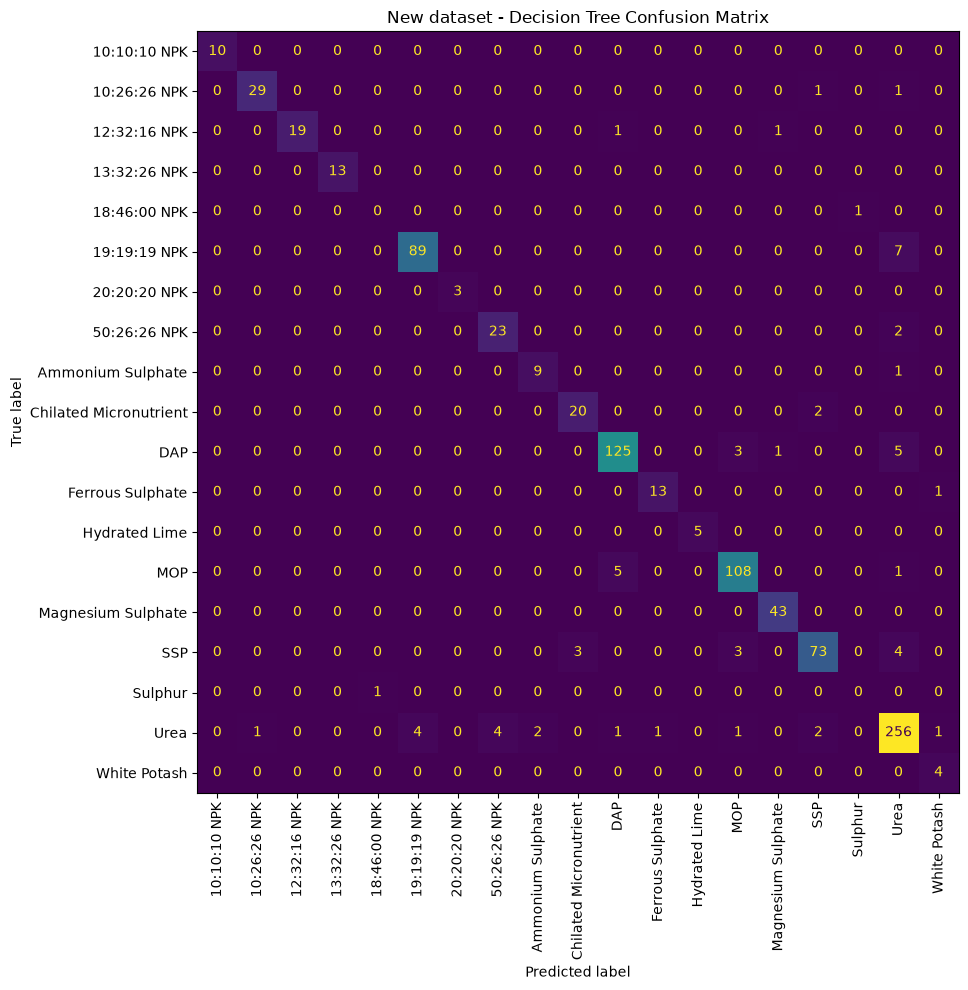

In [8]:
# confusion matrices

def plot_confusion_matrix(
    name,
    y_test,
    predictions,
    mapping,
    filename,
):
    labels = mapping["Target_Label"].tolist()
    names = mapping["Fertilizer"].tolist()

    fig, ax = plt.subplots(figsize=(12, 10))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=labels,
        display_labels=names,
        xticks_rotation=90,
        ax=ax,
        colorbar=False,
    )

    ax.set_title(f"{name} - Decision Tree Confusion Matrix")
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, dpi=150)
    plt.show()

plot_confusion_matrix(
    "Original dataset",
    y_test_original,
    original_pred,
    original_mapping,
    "original_confusion_matrix.png",
)

plot_confusion_matrix(
    "New dataset",
    y_test_new,
    new_pred,
    new_mapping,
    "new_confusion_matrix.png",
)


,Feature,Importance
0,numeric__Temparature,0.159387
1,numeric__Humidity,0.156755
2,numeric__Moisture,0.146093
3,numeric__Nitrogen,0.093050
6,numeric__NPK_Imbalance,0.088012
5,numeric__Phosphorous,0.086388
4,numeric__Potassium,0.055822
15,categorical__Crop Type_Maize,0.018857
7,categorical__Soil Type_Black,0.018364
11,categorical__Soil Type_Sandy,0.017307


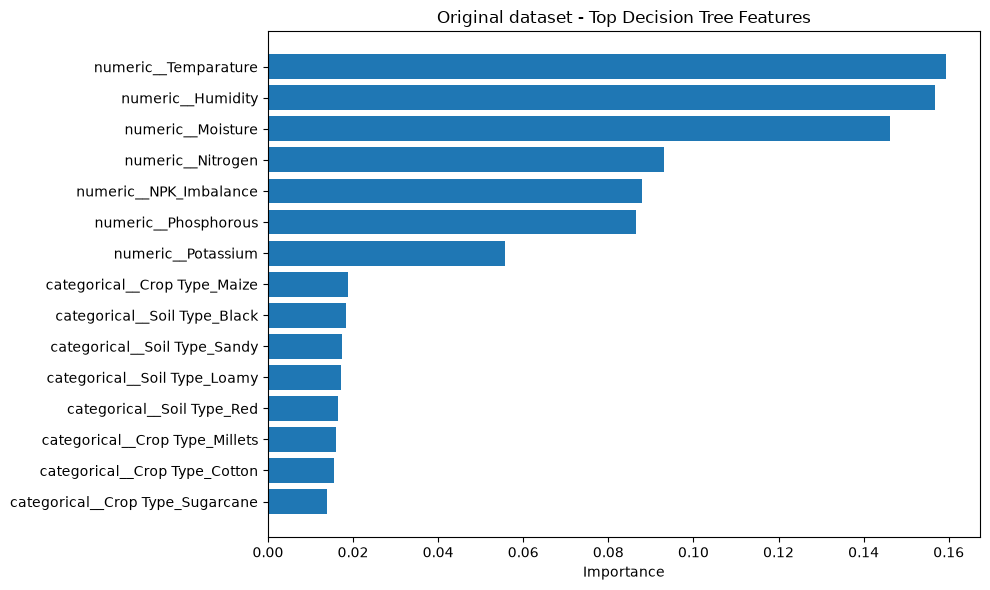

,Feature,Importance
1,numeric__Phosphorus,0.251307
2,numeric__Potassium,0.141918
3,numeric__pH,0.099884
34,categorical__Crop_Wheat,0.077044
4,numeric__Rainfall,0.073455
5,numeric__Temperature,0.071194
19,categorical__Crop_Cotton,0.053966
6,numeric__NPK_Imbalance,0.051351
30,categorical__Crop_Sugarcane,0.032479
28,categorical__Crop_Rice,0.024847


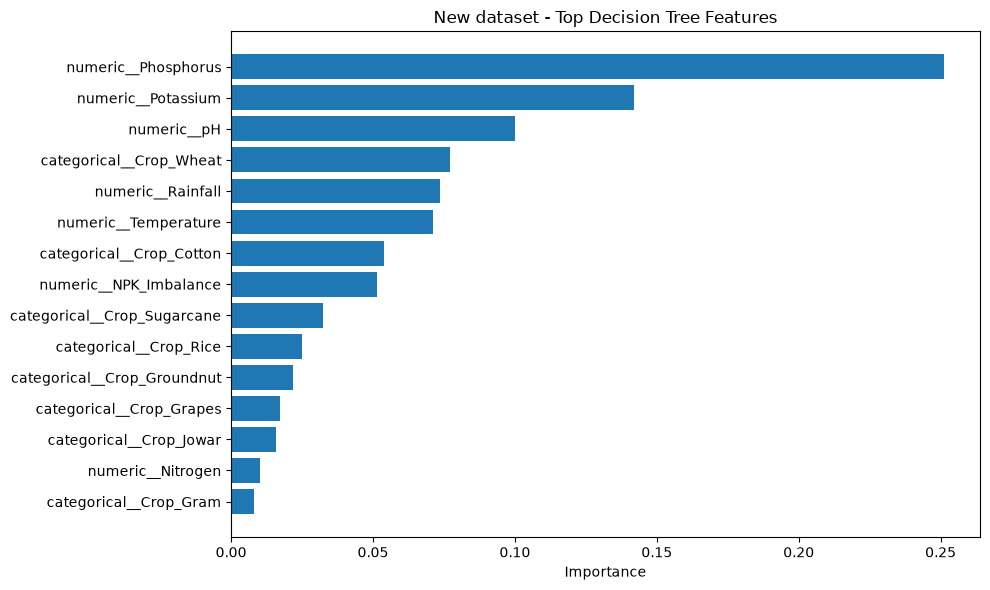

In [9]:
# feature importance

def plot_feature_importance(
    name,
    model,
    feature_names,
    filename,
):
    importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model.feature_importances_,
    }).sort_values(
        "Importance",
        ascending=False,
    )

    display(importance.head(15))

    importance.to_csv(
        RESULT_DIR / filename.replace(".png", ".csv"),
        index=False,
    )

    top = importance.head(15)

    plt.figure(figsize=(10, 6))
    plt.barh(
        top["Feature"][::-1],
        top["Importance"][::-1],
    )
    plt.title(f"{name} - Top Decision Tree Features")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig(
        RESULT_DIR / filename,
        dpi=150,
    )
    plt.show()

plot_feature_importance(
    "Original dataset",
    original_model,
    X_train_original.columns,
    "original_feature_importance.png",
)

plot_feature_importance(
    "New dataset",
    new_model,
    X_train_new.columns,
    "new_feature_importance.png",
)


In [10]:
# summary

for row in results.to_dict(orient="records"):
    print(f"\n{row['Dataset']} dataset")
    print(f"Baseline: {row['Majority_Baseline']:.4f}")
    print(f"Train accuracy: {row['Train_Accuracy']:.4f}")
    print(f"Test accuracy: {row['Test_Accuracy']:.4f}")
    print(f"Macro F1: {row['F1_Macro']:.4f}")
    print(f"Weighted F1: {row['F1_Weighted']:.4f}")
    print(f"5-fold CV accuracy: {row['CV_Accuracy_Mean']:.4f}")



Original dataset
Baseline: 0.1487
Train accuracy: 1.0000
Test accuracy: 0.1462
Macro F1: 0.1460
Weighted F1: 0.1462
5-fold CV accuracy: 0.1381

New dataset
Baseline: 0.3023
Train accuracy: 0.9994
Test accuracy: 0.9324
Macro F1: 0.8368
Weighted F1: 0.9326
5-fold CV accuracy: 0.8967


In [11]:
# tuning

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

def tune_model(
    dataset,
    estimator,
    param_grid,
    X_train,
    y_train,
    X_test,
    y_test,
):
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )

    search.fit(X_train, y_train)

    model = search.best_estimator_
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    tuning_table = pd.DataFrame(search.cv_results_)[[
        "params",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]].sort_values("rank_test_score")

    result = {
        "Dataset": dataset,
        "Variant": "Tuned",
        "Train_Accuracy": accuracy_score(y_train, train_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred),
        "Precision_Weighted": precision_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "Recall_Weighted": recall_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Weighted": f1_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Macro": f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0,
        ),
        "CV_Best_Macro_F1": search.best_score_,
        "Best_Params": str(search.best_params_),
    }

    return model, test_pred, tuning_table, result


In [12]:
# tune both datasets

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 3],
    "class_weight": [None, "balanced"],
}

original_tuned_model, original_tuned_pred, original_tuning, original_tuned_result = tune_model(
    "Original",
    DecisionTreeClassifier(random_state=42),
    param_grid,
    X_train_original,
    y_train_original,
    X_test_original,
    y_test_original,
)

new_tuned_model, new_tuned_pred, new_tuning, new_tuned_result = tune_model(
    "New",
    DecisionTreeClassifier(random_state=42),
    param_grid,
    X_train_new,
    y_train_new,
    X_test_new,
    y_test_new,
)

print("Original best parameters:")
print(original_tuned_result["Best_Params"])

print("\nNew best parameters:")
print(new_tuned_result["Best_Params"])

print("\nOriginal top configurations:")
display(original_tuning.head(5))

print("\nNew top configurations:")
display(new_tuning.head(5))


Original best parameters:
{'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 1}

New best parameters:
{'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1}

Original top configurations:


,params,mean_test_score,std_test_score,rank_test_score
2,"{'class_weight': None, 'criterion': 'gini', 'm...",0.144132,0.007908,1
5,"{'class_weight': None, 'criterion': 'gini', 'm...",0.143593,0.013102,2
3,"{'class_weight': None, 'criterion': 'gini', 'm...",0.143363,0.008912,3
15,"{'class_weight': 'balanced', 'criterion': 'gin...",0.141508,0.007002,4
11,"{'class_weight': None, 'criterion': 'entropy',...",0.141121,0.009223,5



New top configurations:


,params,mean_test_score,std_test_score,rank_test_score
4,"{'class_weight': None, 'criterion': 'gini', 'm...",0.833593,0.029773,1
10,"{'class_weight': None, 'criterion': 'entropy',...",0.822217,0.035221,2
2,"{'class_weight': None, 'criterion': 'gini', 'm...",0.808952,0.038551,3
8,"{'class_weight': None, 'criterion': 'entropy',...",0.800437,0.051350,4
16,"{'class_weight': 'balanced', 'criterion': 'gin...",0.782076,0.048557,5


In [13]:
# tuning comparison

default_comparison = results[[
    "Dataset",
    "Train_Accuracy",
    "Test_Accuracy",
    "Precision_Weighted",
    "Recall_Weighted",
    "F1_Weighted",
    "F1_Macro",
]].copy()

default_comparison.insert(1, "Variant", "Default")
default_comparison["CV_Best_Macro_F1"] = pd.NA
default_comparison["Best_Params"] = "Default parameters"

tuned_comparison = pd.DataFrame([
    original_tuned_result,
    new_tuned_result,
])

comparison = pd.concat(
    [default_comparison, tuned_comparison],
    ignore_index=True,
)

display(comparison.round(4))

comparison.to_csv(
    RESULT_DIR / "decision_tree_tuning_comparison.csv",
    index=False,
)

original_tuning.to_csv(
    RESULT_DIR / "original_tuning_results.csv",
    index=False,
)

new_tuning.to_csv(
    RESULT_DIR / "new_tuning_results.csv",
    index=False,
)


,Dataset,Variant,Train_Accuracy,Test_Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,F1_Macro,CV_Best_Macro_F1,Best_Params
0,Original,Default,1.0000,0.1462,0.1463,0.1462,0.1462,0.1460,<NA>,Default parameters
1,New,Default,0.9994,0.9324,0.9337,0.9324,0.9326,0.8368,<NA>,Default parameters
2,Original,Tuned,0.7583,0.1450,0.1439,0.1450,0.1442,0.1442,0.144132,"{'class_weight': None, 'criterion': 'gini', 'm..."
3,New,Tuned,0.9994,0.9324,0.9337,0.9324,0.9326,0.8368,0.833593,"{'class_weight': None, 'criterion': 'gini', 'm..."


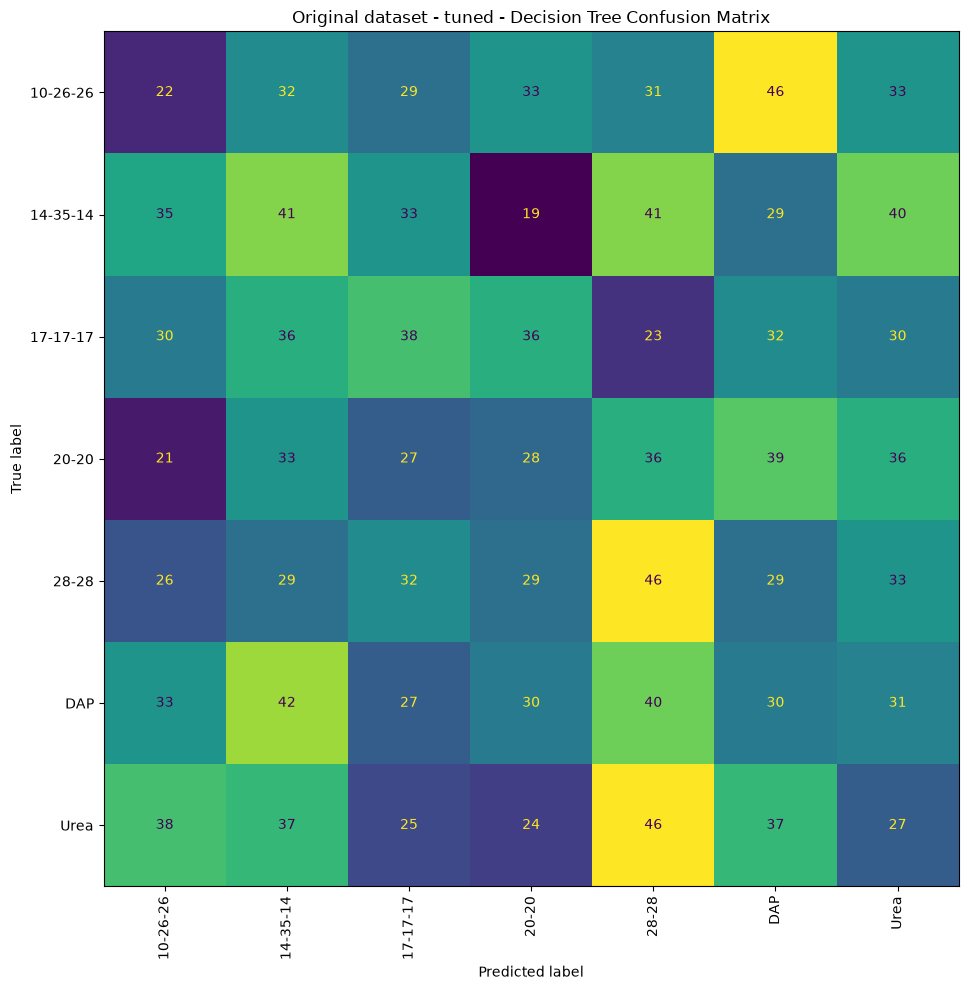

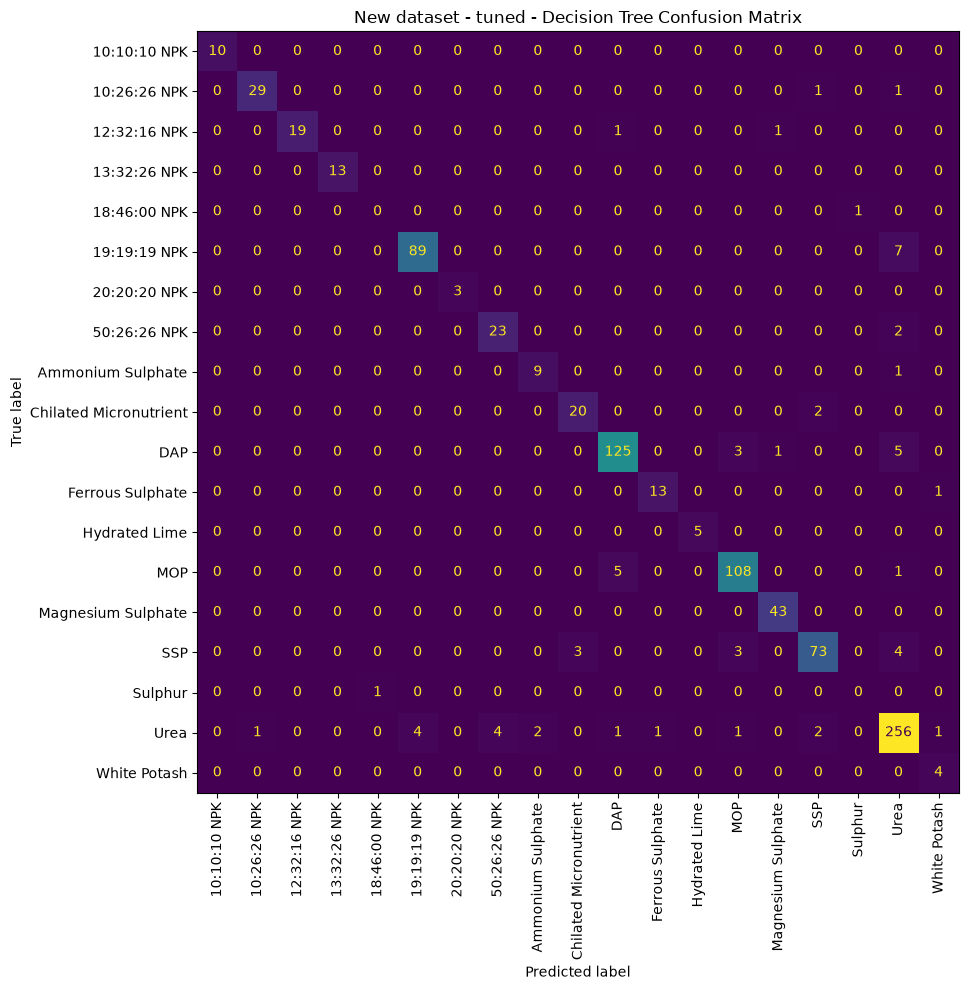

In [14]:
# tuned confusion matrices

plot_confusion_matrix(
    "Original dataset - tuned",
    y_test_original,
    original_tuned_pred,
    original_mapping,
    "original_tuned_confusion_matrix.png",
)

plot_confusion_matrix(
    "New dataset - tuned",
    y_test_new,
    new_tuned_pred,
    new_mapping,
    "new_tuned_confusion_matrix.png",
)


In [15]:
# tuned summary

for row in tuned_comparison.to_dict(orient="records"):
    print(f"\n{row['Dataset']} dataset")
    print(f"Best parameters: {row['Best_Params']}")
    print(f"Test accuracy: {row['Test_Accuracy']:.4f}")
    print(f"Weighted F1: {row['F1_Weighted']:.4f}")
    print(f"Macro F1: {row['F1_Macro']:.4f}")
    print(f"Best 5-fold CV macro F1: {row['CV_Best_Macro_F1']:.4f}")



Original dataset
Best parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 1}
Test accuracy: 0.1450
Weighted F1: 0.1442
Macro F1: 0.1442
Best 5-fold CV macro F1: 0.1441

New dataset
Best parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1}
Test accuracy: 0.9324
Weighted F1: 0.9326
Macro F1: 0.8368
Best 5-fold CV macro F1: 0.8336
